<a href="https://colab.research.google.com/github/Prachi472006/major-project/blob/main/CreditLens_Colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install catboost streamlit plotly

In [ ]:
import os, json, warnings, shutil, time
warnings.filterwarnings('ignore')
SEED=42; DATA='/content/data'; ROOT='/content/creditlens'; ART=ROOT+'/artifacts'
SAMPLE_FRAC=1.0   # 0.3 for a quick test
os.makedirs(DATA,exist_ok=True); os.makedirs(ART,exist_ok=True)

!pip -q install -U kaggle
from google.colab import files
import getpass
# Kaggle login: paste a new-style API token, or press Enter and upload a legacy kaggle.json
tok=getpass.getpass('KGAT_c9d695133d5391a0afbc0195b7a2a228 ').strip()
if tok:
    os.environ['KAGGLE_API_TOKEN']=tok
else:
    files.upload()
    !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c home-credit-default-risk -p /content/data
!cd /content/data && unzip -oq home-credit-default-risk.zip

KGAT_c9d695133d5391a0afbc0195b7a2a228 ··········
100% 688M/688M [00:08<00:00, 81.9MB/s]



In [ ]:
import numpy as np, pandas as pd
def load(n,c):
    d=pd.read_csv(f'{DATA}/{n}.csv',usecols=c); return d[d.SK_ID_CURR.isin(keep)]
app=pd.read_csv(f'{DATA}/application_train.csv')
if SAMPLE_FRAC<1: app=app.sample(frac=SAMPLE_FRAC,random_state=SEED).reset_index(drop=True)
keep=set(app.SK_ID_CURR)
feat=pd.DataFrame(index=pd.Index(app.SK_ID_CURR,name='SK_ID_CURR'))

# Alternative data 1: instalment payment behaviour (utility / bill payment proxy)
ip=load('installments_payments',['SK_ID_CURR','DAYS_INSTALMENT','DAYS_ENTRY_PAYMENT','AMT_INSTALMENT','AMT_PAYMENT'])
ip['dl']=ip.DAYS_ENTRY_PAYMENT-ip.DAYS_INSTALMENT; ip['late']=(ip.dl>0).astype('float32'); ip['dlp']=ip.dl.clip(lower=0)
ip['paid']=ip.AMT_PAYMENT/ip.AMT_INSTALMENT.replace(0,np.nan); ip['under']=(ip.paid<.99).astype('float32')
feat=feat.join(ip.groupby('SK_ID_CURR').agg(inst_cnt=('late','size'),inst_late_share=('late','mean'),inst_days_late_mean=('dlp','mean'),
    inst_days_late_max=('dlp','max'),inst_paid_ratio_mean=('paid','mean'),inst_underpaid_share=('under','mean')))
feat=feat.join(ip[ip.DAYS_INSTALMENT>=-365].groupby('SK_ID_CURR').late.mean().rename('inst_late_share_1y')); del ip

# Alternative data 2: cash-flow and account activity (transaction / UPI proxy)
ps=load('POS_CASH_balance',['SK_ID_CURR','SK_DPD','SK_DPD_DEF']); ps['dd']=(ps.SK_DPD_DEF>0).astype('float32')
feat=feat.join(ps.groupby('SK_ID_CURR').agg(pos_cnt=('dd','size'),pos_dpd_mean=('SK_DPD','mean'),pos_dpd_max=('SK_DPD','max'),pos_dpd_def_share=('dd','mean'))); del ps
cc=load('credit_card_balance',['SK_ID_CURR','AMT_BALANCE','AMT_CREDIT_LIMIT_ACTUAL','AMT_DRAWINGS_CURRENT','SK_DPD'])
cc['util']=cc.AMT_BALANCE/cc.AMT_CREDIT_LIMIT_ACTUAL.replace(0,np.nan)
feat=feat.join(cc.groupby('SK_ID_CURR').agg(cc_cnt=('util','size'),cc_util_mean=('util','mean'),cc_util_max=('util','max'),
    cc_drawings_mean=('AMT_DRAWINGS_CURRENT','mean'),cc_dpd_mean=('SK_DPD','mean'))); del cc

# External bureau history and previous applications
b=load('bureau',['SK_ID_CURR','CREDIT_ACTIVE','AMT_CREDIT_SUM','AMT_CREDIT_SUM_DEBT','AMT_CREDIT_SUM_OVERDUE','CREDIT_DAY_OVERDUE','DAYS_CREDIT'])
b['act']=(b.CREDIT_ACTIVE=='Active').astype('float32')
feat=feat.join(b.groupby('SK_ID_CURR').agg(bureau_cnt=('act','size'),bureau_active_cnt=('act','sum'),bureau_debt_sum=('AMT_CREDIT_SUM_DEBT','sum'),
    bureau_overdue_sum=('AMT_CREDIT_SUM_OVERDUE','sum'),bureau_max_day_overdue=('CREDIT_DAY_OVERDUE','max'),bureau_credit_sum=('AMT_CREDIT_SUM','sum'),
    bureau_days_credit_mean=('DAYS_CREDIT','mean'))); del b
pv=load('previous_application',['SK_ID_CURR','NAME_CONTRACT_STATUS','AMT_APPLICATION'])
pv['ok']=(pv.NAME_CONTRACT_STATUS=='Approved').astype('float32'); pv['no']=(pv.NAME_CONTRACT_STATUS=='Refused').astype('float32')
feat=feat.join(pv.groupby('SK_ID_CURR').agg(prev_cnt=('ok','size'),prev_approved_cnt=('ok','sum'),prev_refused_cnt=('no','sum'),
    prev_refused_share=('no','mean'),prev_amt_application_mean=('AMT_APPLICATION','mean'))); del pv

CNT=[c for c in feat.columns if c.endswith('_cnt')]; feat[CNT]=feat[CNT].fillna(0)
feat['thin_file']=(feat.bureau_cnt==0).astype('int8')   # no bureau records = credit invisible
ALT=list(feat.columns)

# Traditional application features
d=app.copy()
d['DAYS_EMPLOYED']=d.DAYS_EMPLOYED.replace(365243,np.nan)
d['age_years']=-d.DAYS_BIRTH/365; d['employed_years']=-d.DAYS_EMPLOYED/365; d['phone_change_years']=-d.DAYS_LAST_PHONE_CHANGE/365
d['credit_income_ratio']=d.AMT_CREDIT/d.AMT_INCOME_TOTAL; d['annuity_income_ratio']=d.AMT_ANNUITY/d.AMT_INCOME_TOTAL
d['credit_goods_ratio']=d.AMT_CREDIT/d.AMT_GOODS_PRICE; d['annuity_credit_ratio']=d.AMT_ANNUITY/d.AMT_CREDIT
d['employed_to_age']=d.employed_years/d.age_years; d['income_per_person']=d.AMT_INCOME_TOTAL/d.CNT_FAM_MEMBERS.clip(lower=1)
d['docs_provided']=d.filter(like='FLAG_DOCUMENT').sum(axis=1)
ext=d[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']]; d['ext_mean']=ext.mean(axis=1); d['ext_prod']=ext.prod(axis=1,skipna=False)
drop=['DAYS_BIRTH','DAYS_EMPLOYED','DAYS_LAST_PHONE_CHANGE','WEEKDAY_APPR_PROCESS_START','HOUR_APPR_PROCESS_START']
drop+=[c for c in d.columns if c.startswith('FLAG_DOCUMENT') or c.endswith(('_AVG','_MODE','_MEDI'))]
d=d.drop(columns=drop).merge(feat.reset_index(),on='SK_ID_CURR',how='left')

# Fairness: gender is NOT a model feature; kept only for auditing
audit=d[['CODE_GENDER','age_years','NAME_EDUCATION_TYPE']].copy()
y=d.TARGET.values; sid=d.SK_ID_CURR.values
X=d.drop(columns=['SK_ID_CURR','TARGET','CODE_GENDER']).replace([np.inf,-np.inf],np.nan)
CAT=[c for c in X.columns if X[c].dtype=='object']
for c in X.columns: X[c]=X[c].fillna('Unknown').astype(str) if c in CAT else X[c].astype('float32')
TRAD=[c for c in X.columns if c not in ALT]
print(X.shape,'default rate',y.mean().round(4),'thin-file share',X.thin_file.mean().round(3))

(307511, 88) default rate 0.0807 thin-file share 0.143


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier, Pool

idx=np.arange(len(X)); tr,te=train_test_split(idx,test_size=.15,stratify=y,random_state=SEED)
tr,va=train_test_split(tr,test_size=.1765,stratify=y[tr],random_state=SEED)   # 70/15/15 stratified

def best_thr(yt,p):   # F2-optimal threshold on validation data: recall matters more than precision
    pr,rc,th=precision_recall_curve(yt,p); f2=5*pr[:-1]*rc[:-1]/np.maximum(4*pr[:-1]+rc[:-1],1e-9); return float(th[f2.argmax()])
def evaluate(yt,p,t):
    fpr,tpr,_=roc_curve(yt,p); pr=(p>=t).astype(int); tn,fp,fn,tp=confusion_matrix(yt,pr).ravel()
    return dict(roc_auc=float(roc_auc_score(yt,p)),pr_auc=float(average_precision_score(yt,p)),ks=float((tpr-fpr).max()),threshold=float(t),
        accuracy=float(accuracy_score(yt,pr)),precision=float(precision_score(yt,pr)),recall=float(recall_score(yt,pr)),f1=float(f1_score(yt,pr)),
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

Xn=X.copy()
for c in CAT: Xn[c]=Xn[c].astype('category').cat.codes.astype('float32')   # ordinal codes for non-CatBoost models
res={}; P={}
def add(name,pv,pt):
    t=best_thr(y[va],pv); res[name]=evaluate(y[te],pt,t); P[name]=pt; print(name,{k:round(v,3) for k,v in res[name].items() if k in('roc_auc','recall','precision','f1')})

m=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(C=.1,class_weight='balanced',max_iter=300)).fit(Xn.iloc[tr],y[tr])
add('Logistic Regression',m.predict_proba(Xn.iloc[va])[:,1],m.predict_proba(Xn.iloc[te])[:,1])
m=make_pipeline(SimpleImputer(strategy='median'),RandomForestClassifier(300,max_depth=12,min_samples_leaf=50,class_weight='balanced_subsample',n_jobs=-1,random_state=SEED)).fit(Xn.iloc[tr],y[tr])
add('Random Forest',m.predict_proba(Xn.iloc[va])[:,1],m.predict_proba(Xn.iloc[te])[:,1])
m=XGBClassifier(n_estimators=800,learning_rate=.05,max_depth=5,subsample=.8,colsample_bytree=.7,tree_method='hist',eval_metric='auc',early_stopping_rounds=50,n_jobs=-1,random_state=SEED)
m.fit(Xn.iloc[tr],y[tr],eval_set=[(Xn.iloc[va],y[va])],verbose=False)
add('XGBoost',m.predict_proba(Xn.iloc[va])[:,1],m.predict_proba(Xn.iloc[te])[:,1])

def fit_cb(cols):
    cb=CatBoostClassifier(iterations=1500,learning_rate=.05,depth=6,eval_metric='AUC',random_seed=SEED,od_type='Iter',od_wait=100,verbose=250)  # task_type='GPU' if available
    cb.fit(X.iloc[tr][cols],y[tr],cat_features=[c for c in cols if c in CAT],eval_set=(X.iloc[va][cols],y[va]),use_best_model=True); return cb
cb_trad=fit_cb(TRAD)
add('CatBoost (traditional only)',cb_trad.predict_proba(X.iloc[va][TRAD])[:,1],cb_trad.predict_proba(X.iloc[te][TRAD])[:,1])
cb=fit_cb(list(X.columns))
pva=cb.predict_proba(X.iloc[va])[:,1]; pte=cb.predict_proba(X.iloc[te])[:,1]
add('CatBoost (traditional + alternative)',pva,pte)
comp=pd.DataFrame(res).T.round(4); comp.to_csv(ART+'/comparison.csv'); comp[['roc_auc','pr_auc','ks','precision','recall','f1','accuracy']]

Logistic Regression {'roc_auc': 0.763, 'precision': 0.179, 'recall': 0.654, 'f1': 0.281}
Random Forest {'roc_auc': 0.763, 'precision': 0.179, 'recall': 0.657, 'f1': 0.281}
XGBoost {'roc_auc': 0.782, 'precision': 0.19, 'recall': 0.678, 'f1': 0.297}
0:	test: 0.6475327	best: 0.6475327 (0)	total: 696ms	remaining: 17m 23s
250:	test: 0.7625139	best: 0.7625139 (250)	total: 2m 40s	remaining: 13m 19s
500:	test: 0.7678342	best: 0.7678342 (500)	total: 5m 20s	remaining: 10m 38s
750:	test: 0.7690575	best: 0.7690575 (750)	total: 8m 5s	remaining: 8m 3s
1000:	test: 0.7696766	best: 0.7696852 (998)	total: 10m 43s	remaining: 5m 20s
1250:	test: 0.7699131	best: 0.7699399 (1223)	total: 13m 24s	remaining: 2m 40s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7699398609
bestIteration = 1223

Shrink model to first 1224 iterations.
CatBoost (traditional only) {'roc_auc': 0.772, 'precision': 0.182, 'recall': 0.66, 'f1': 0.286}
0:	test: 0.6726032	best: 0.6726032 (0)	total: 595ms	remaining: 1

,roc_auc,pr_auc,ks,precision,recall,f1,accuracy
Logistic Regression,0.7627,0.2454,0.3935,0.1786,0.6544,0.2806,0.7291
Random Forest,0.7635,0.2512,0.3993,0.1791,0.6566,0.2814,0.7293
XGBoost,0.7824,0.2784,0.4261,0.1900,0.6778,0.2969,0.7408
CatBoost (traditional only),0.7717,0.2588,0.4028,0.1825,0.6603,0.2859,0.7337
CatBoost (traditional + alternative),0.7844,0.2820,0.4298,0.1875,0.6882,0.2947,0.7340


        applicants  default_rate
band                            
Low          20566        0.0214
Medium       11890        0.0606
High         13671        0.1875
AUC by file type {'thin_file': 0.7747888806379749, 'thick_file': 0.7848487722931177}
mean predicted PD 0.0797 actual 0.0807


,attribute,group,n,default_rate,flag_rate,fpr,fnr
0,CODE_GENDER,F,30390,0.0697,0.2643,0.2353,0.3492
1,CODE_GENDER,M,15735,0.1020,0.3584,0.3153,0.2623
2,age_band,<30,6533,0.1160,0.4710,0.4287,0.2071
3,age_band,30-45,18565,0.0872,0.3375,0.2989,0.2582
4,age_band,45-60,15543,0.0685,0.2318,0.2040,0.3891
5,age_band,60+,5486,0.0516,0.1322,0.1180,0.6078
6,NAME_EDUCATION_TYPE,Higher education,11279,0.0513,0.1733,0.1532,0.4542
7,NAME_EDUCATION_TYPE,Incomplete higher,1475,0.0807,0.3308,0.2994,0.3109
8,NAME_EDUCATION_TYPE,Lower secondary,591,0.1134,0.3621,0.3206,0.3134
9,NAME_EDUCATION_TYPE,Secondary / secondary special,32751,0.0903,0.3361,0.2984,0.2836


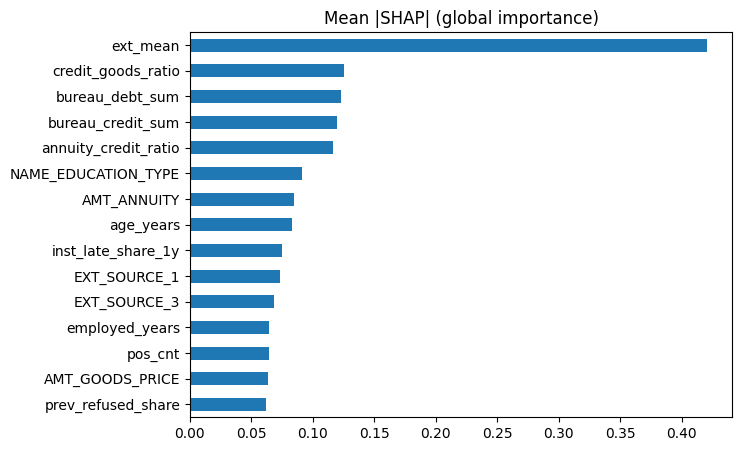

In [ ]:
THR=res['CatBoost (traditional + alternative)']['threshold']; LOW=THR*.5
band=np.where(pte>=THR,'High',np.where(pte>=LOW,'Medium','Low'))
bt=pd.DataFrame({'band':band,'y':y[te]}).groupby('band').agg(applicants=('y','size'),default_rate=('y','mean')).reindex(['Low','Medium','High']); print(bt.round(4))
thin=(X.iloc[te].thin_file==1).values
tv={k:float(roc_auc_score(y[te][m],pte[m])) for k,m in {'thin_file':thin,'thick_file':~thin}.items()}; print('AUC by file type',tv)
print('mean predicted PD',pte.mean().round(4),'actual',y[te].mean().round(4))

# Explainability: exact SHAP values from CatBoost, global importance
smp=X.iloc[te].sample(3000,random_state=SEED)
sv=cb.get_feature_importance(Pool(smp,cat_features=CAT),type='ShapValues')[:,:-1]
imp=pd.Series(np.abs(sv).mean(0),index=X.columns).sort_values(ascending=False); imp.head(25).to_csv(ART+'/importance.csv')
imp.head(15)[::-1].plot.barh(figsize=(7,5),title='Mean |SHAP| (global importance)')

# Fairness audit at the production threshold
a=audit.iloc[te].copy(); a['y']=y[te]; a['flag']=(pte>=THR).astype(int)
a['age_band']=pd.cut(a.age_years,[0,30,45,60,120],labels=['<30','30-45','45-60','60+'])
rows=[]
for col in ['CODE_GENDER','age_band','NAME_EDUCATION_TYPE']:
    for g,s in a.groupby(col,observed=True):
        if len(s)<100: continue
        rows.append(dict(attribute=col,group=str(g),n=len(s),default_rate=s.y.mean(),flag_rate=s.flag.mean(),
            fpr=s[s.y==0].flag.mean(),fnr=1-s[s.y==1].flag.mean()))
fair=pd.DataFrame(rows).round(4); fair.to_csv(ART+'/fairness.csv',index=False); fair

In [ ]:
LABELS={'ext_mean':'External credit score (average)','EXT_SOURCE_1':'External score 1','EXT_SOURCE_2':'External score 2','EXT_SOURCE_3':'External score 3','ext_prod':'External scores combined',
'inst_late_share':'Share of late instalments','inst_late_share_1y':'Late instalments in last year','inst_days_late_mean':'Average days late','inst_days_late_max':'Maximum days late',
'inst_paid_ratio_mean':'Payment to instalment ratio','inst_underpaid_share':'Share of underpaid instalments','cc_util_mean':'Credit card utilisation','cc_util_max':'Peak card utilisation',
'cc_dpd_mean':'Card days past due','pos_dpd_mean':'Instalment loan days past due','prev_refused_cnt':'Previous refused applications','prev_refused_share':'Share of refused applications',
'prev_approved_cnt':'Previous approved applications','bureau_overdue_sum':'Bureau overdue amount','bureau_cnt':'Number of bureau credits','bureau_debt_sum':'Bureau outstanding debt',
'credit_income_ratio':'Loan to annual income','annuity_income_ratio':'Repayment to income','credit_goods_ratio':'Loan to goods price','annuity_credit_ratio':'Annuity to loan amount',
'age_years':'Age','employed_years':'Years employed','employed_to_age':'Employment share of life','phone_change_years':'Years since phone change','AMT_INCOME_TOTAL':'Annual income',
'AMT_CREDIT':'Loan amount','AMT_ANNUITY':'Annual repayment','AMT_GOODS_PRICE':'Goods price','thin_file':'No bureau history','NAME_EDUCATION_TYPE':'Education','NAME_INCOME_TYPE':'Income type',
'NAME_FAMILY_STATUS':'Family status','OCCUPATION_TYPE':'Occupation','ORGANIZATION_TYPE':'Employer type','DAYS_ID_PUBLISH':'Days since ID issued','DAYS_REGISTRATION':'Days since registration'}
num=[c for c in X.columns if c not in CAT]
meta=dict(model_version='creditlens-cb-1.0',trained=time.strftime('%Y-%m-%d'),features=list(X.columns),cat_features=CAT,labels=LABELS,
    defaults={**{c:float(X.iloc[tr][c].median()) for c in num},**{c:X.iloc[tr][c].mode()[0] for c in CAT}},
    cat_values={c:sorted(X[c].unique().tolist())[:60] for c in CAT},threshold=THR,low_cut=LOW,
    test=res['CatBoost (traditional + alternative)'],ablation_auc={'traditional':res['CatBoost (traditional only)']['roc_auc'],'with_alternative':res['CatBoost (traditional + alternative)']['roc_auc']},
    thin_thick_auc=tv,bands=bt.reset_index().to_dict('records'),pd_edges=np.quantile(pte,np.linspace(0,1,11)).tolist(),
    n_train=int(len(tr)),default_rate=float(y.mean()))
json.dump(meta,open(ART+'/meta.json','w'),indent=1)
cb.save_model(ART+'/model.cbm')
s=X.iloc[te].sample(2000,random_state=SEED).copy(); s.insert(0,'SK_ID_CURR',sid[s.index]); s['TARGET']=y[s.index]
s.to_csv(ART+'/sample_applicants.csv',index=False)
print('saved',os.listdir(ART))

saved ['meta.json', 'model.cbm', 'sample_applicants.csv', 'fairness.csv', 'comparison.csv', 'importance.csv']


In [ ]:
%%writefile /content/creditlens/app.py
import json, sqlite3, os
from pathlib import Path
import numpy as np, pandas as pd, streamlit as st, plotly.graph_objects as go
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score

ROOT = Path(__file__).parent; ART = ROOT / "artifacts"
st.set_page_config(page_title="CreditLens", page_icon="📊", layout="wide")

@st.cache_resource
def load():
    meta = json.loads((ART / "meta.json").read_text())
    m = CatBoostClassifier(); m.load_model(str(ART / "model.cbm"))
    return meta, m, pd.read_csv(ART / "sample_applicants.csv")
meta, model, sample = load()
FE, CATS, DEF, THR, LOW, LAB = meta["features"], meta["cat_features"], meta["defaults"], meta["threshold"], meta["low_cut"], meta["labels"]
ACTION = {"Low": "Proceed to standard processing", "Medium": "Manual underwriting review", "High": "Escalate for detailed assessment and additional verification"}
COL = {"Low": "#188a5c", "Medium": "#d98a00", "High": "#c93c3c"}
lab = lambda f: LAB.get(f, f.replace("_", " "))
band = lambda p: "High" if p >= THR else ("Medium" if p >= LOW else "Low")

def prep(df):
    X = pd.DataFrame(index=df.index)
    for c in FE:
        v = df[c] if c in df.columns else pd.Series(DEF[c], index=df.index)
        X[c] = v.fillna("Unknown").astype(str) if c in CATS else pd.to_numeric(v, errors="coerce").astype("float32")
    return X
score = lambda X: model.predict_proba(X)[:, 1]
shap = lambda X: model.get_feature_importance(Pool(X, cat_features=CATS), type="ShapValues")[:, :-1]

@st.cache_data
def ref_scores(): return score(prep(sample))
REF = ref_scores()

def psi(p):
    e = np.array(meta["pd_edges"]); e[0], e[-1] = -1, 2
    a = np.clip(np.histogram(p, bins=e)[0] / len(p), 1e-4, None); b = np.full(10, .1)
    return float(((a - b) * np.log(a / b)).sum())

def db():
    c = sqlite3.connect(ROOT / "audit.db")
    c.execute("create table if not exists audit(ts text, applicant_ref text, pd real, band text, model text, action text, note text, analyst text)")
    return c

def gauge(p):
    top = min(1, max(.4, THR * 2.2))
    f = go.Figure(go.Indicator(mode="gauge+number", value=p * 100, number={"suffix": "%", "valueformat": ".1f"},
        gauge={"axis": {"range": [0, top * 100]}, "bar": {"color": COL[band(p)]},
               "steps": [{"range": [0, LOW * 100], "color": "#d8efe5"}, {"range": [LOW * 100, THR * 100], "color": "#fbeccb"}, {"range": [THR * 100, top * 100], "color": "#f6d5d5"}]}))
    f.update_layout(height=240, margin=dict(t=20, b=0, l=20, r=20)); return f

def derive(r):
    inc = max(float(r["AMT_INCOME_TOTAL"]), 1)
    r["credit_income_ratio"] = r["AMT_CREDIT"] / inc; r["annuity_income_ratio"] = r["AMT_ANNUITY"] / inc
    r["credit_goods_ratio"] = r["AMT_CREDIT"] / r["AMT_GOODS_PRICE"] if r["AMT_GOODS_PRICE"] > 0 else np.nan
    r["annuity_credit_ratio"] = r["AMT_ANNUITY"] / r["AMT_CREDIT"] if r["AMT_CREDIT"] > 0 else np.nan
    r["employed_to_age"] = r["employed_years"] / max(r["age_years"], 1)
    if "CNT_FAM_MEMBERS" in r.index: r["income_per_person"] = inc / max(float(r["CNT_FAM_MEMBERS"]), 1)
    return r

page = st.sidebar.radio("CreditLens", ["Assess applicant", "Portfolio scoring", "Model governance", "Audit log"])
st.sidebar.caption(f"Model {meta['model_version']} · trained {meta['trained']}")

if page == "Assess applicant":
    st.title("Applicant risk assessment")
    mode = st.radio("Start from", ["Portfolio average profile", "Holdout applicant"], horizontal=True)
    if mode == "Holdout applicant":
        sid = st.selectbox("Applicant ID", sample.SK_ID_CURR.tolist()[:300]); base = sample[sample.SK_ID_CURR == sid].iloc[0]; ref = str(sid)
    else: base, ref = pd.Series(DEF), "manual"
    row = pd.Series({c: (base[c] if c in base.index and pd.notna(base[c]) else DEF[c]) for c in FE})
    k = lambda n: f"{n}_{ref}"
    a, b, c = st.columns(3)
    with a:
        st.subheader("Applicant")
        row["age_years"] = st.slider("Age", 20, 70, int(row["age_years"]), key=k("age"))
        row["employed_years"] = st.number_input("Years employed", 0.0, 50.0, float(np.nan_to_num(row["employed_years"], nan=DEF["employed_years"])), key=k("emp"))
        for f, t in [("NAME_EDUCATION_TYPE", "Education"), ("NAME_INCOME_TYPE", "Income type"), ("NAME_FAMILY_STATUS", "Family status")]:
            o = meta["cat_values"][f]; row[f] = st.selectbox(t, o, o.index(row[f]) if row[f] in o else 0, key=k(f))
    with b:
        st.subheader("Loan")
        for f, t in [("AMT_INCOME_TOTAL", "Annual income"), ("AMT_CREDIT", "Loan amount"), ("AMT_ANNUITY", "Annual repayment"), ("AMT_GOODS_PRICE", "Goods price")]:
            row[f] = st.number_input(t, 0.0, 1e8, float(np.nan_to_num(row[f], nan=DEF[f])), step=1000.0, key=k(f))
        for f in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
            row[f] = st.slider(lab(f), 0.0, 1.0, float(np.nan_to_num(row[f], nan=DEF[f])), .01, key=k(f))
    with c:
        st.subheader("Alternative data")
        thin = st.checkbox("No bureau history (thin file)", value=bool(row["bureau_cnt"] == 0), key=k("thin"))
        row["inst_late_share"] = st.slider("Share of late instalments", 0.0, 1.0, float(np.nan_to_num(row["inst_late_share"], nan=0)), .01, key=k("ils"))
        row["inst_days_late_mean"] = st.slider("Average days late", 0.0, 30.0, float(min(np.nan_to_num(row["inst_days_late_mean"], nan=0), 30)), .5, key=k("idl"))
        row["inst_paid_ratio_mean"] = st.slider("Payment to instalment ratio", 0.0, 2.0, float(min(np.nan_to_num(row["inst_paid_ratio_mean"], nan=1), 2)), .01, key=k("ipr"))
        row["cc_util_mean"] = st.slider("Card utilisation", 0.0, 1.5, float(min(np.nan_to_num(row["cc_util_mean"], nan=0), 1.5)), .01, key=k("ccu"))
        row["prev_refused_cnt"] = st.number_input("Previous refusals", 0, 30, int(row["prev_refused_cnt"]), key=k("prf"))
        row["phone_change_years"] = st.slider("Years since phone change", 0.0, 10.0, float(min(np.nan_to_num(row["phone_change_years"], nan=1), 10)), .1, key=k("pch"))
        if not thin: row["bureau_overdue_sum"] = st.number_input("Bureau overdue amount", 0.0, 1e8, float(np.nan_to_num(row["bureau_overdue_sum"], nan=0)), step=500.0, key=k("bov"))
    if thin:
        for f in [x for x in FE if x.startswith("bureau_")]: row[f] = 0 if f.endswith("_cnt") else np.nan
    row["thin_file"] = int(thin); row = derive(row)
    X1 = prep(pd.DataFrame([row])); p = float(score(X1)[0]); sv = shap(X1)[0]; bd = band(p)
    st.divider(); g, r = st.columns([1, 2])
    with g:
        st.plotly_chart(gauge(p), use_container_width=True)
        st.markdown(f"<h3 style='color:{COL[bd]};margin:0'>{bd} risk</h3>", unsafe_allow_html=True)
        st.write(f"**{ACTION[bd]}**"); st.caption(f"Riskier than {(REF < p).mean() * 100:.0f}% of the holdout portfolio")
    with r:
        o = np.argsort(-np.abs(sv))[:8][::-1]
        f = go.Figure(go.Bar(x=sv[o], y=[lab(FE[i]) for i in o], orientation="h", marker_color=[COL["High"] if sv[i] > 0 else COL["Low"] for i in o]))
        f.update_layout(height=300, margin=dict(t=30, b=10, l=10, r=10), title="Factors in this assessment (red raises risk, green lowers it)"); st.plotly_chart(f, use_container_width=True)
    up = [i for i in np.argsort(-sv)[:3] if sv[i] > 0]
    if up: st.write("**Main reasons for elevated risk:** " + "; ".join(f"{lab(FE[i])} ({X1.iloc[0, i] if FE[i] in CATS else round(float(X1.iloc[0, i]), 2)})" for i in up))
    st.subheader("Analyst decision")
    with st.form("dec"):
        x1, x2 = st.columns(2); act = x1.selectbox("Action", list(ACTION.values()) + ["Request additional documents"]); who = x2.text_input("Analyst ID")
        note = st.text_area("Rationale (required if the action differs from the recommendation)")
        if st.form_submit_button("Save to audit log"):
            if not who or (act != ACTION[bd] and not note): st.error("Analyst ID and a rationale for overrides are required.")
            else:
                c = db(); c.execute("insert into audit values(datetime('now'),?,?,?,?,?,?,?)", (ref, p, bd, meta["model_version"], act, note, who)); c.commit(); st.success("Saved.")
    st.info("This prediction is a decision-support estimate and not a final lending decision. Human judgement and institutional policy apply.")

elif page == "Portfolio scoring":
    st.title("Portfolio scoring")
    up = st.file_uploader("Upload applicants (CSV with model feature names; missing columns use portfolio defaults)", type="csv")
    df = pd.read_csv(up) if up else (sample if st.button("Use demo portfolio (holdout sample)") else None)
    if df is not None:
        df = df.head(20000); X = prep(df); p = score(X); sv = shap(X)
        out = pd.DataFrame({"applicant": df["SK_ID_CURR"] if "SK_ID_CURR" in df else df.index, "default_probability": p.round(4)})
        out["band"] = [band(v) for v in p]; out["recommended_action"] = out.band.map(ACTION)
        out["top_reasons"] = ["; ".join(lab(FE[i]) for i in np.argsort(-s)[:3] if s[i] > 0) for s in sv]
        m1, m2, m3, m4 = st.columns(4); m1.metric("Applicants", len(out)); m2.metric("Average PD", f"{p.mean():.1%}")
        m3.metric("High-risk share", f"{(out.band == 'High').mean():.1%}"); ps = psi(p); m4.metric("Score drift (PSI)", f"{ps:.3f}", "stable" if ps < .1 else ("monitor" if ps < .25 else "retrain"), delta_color="off")
        st.plotly_chart(go.Figure(go.Histogram(x=p, nbinsx=50)).update_layout(height=260, title="Distribution of default probability"), use_container_width=True)
        if "TARGET" in df:
            st.write(f"Back-test ROC-AUC: **{roc_auc_score(df.TARGET, p):.3f}**"); st.dataframe(pd.DataFrame({"band": out.band, "defaulted": df.TARGET.values}).groupby("band").defaulted.agg(["size", "mean"]).rename(columns={"size": "applicants", "mean": "actual default rate"}))
        st.dataframe(out, use_container_width=True); st.download_button("Download scored portfolio", out.to_csv(index=False), "scored_portfolio.csv")

elif page == "Model governance":
    st.title("Model governance")
    t = meta["test"]; c = st.columns(5)
    for col, (n, v) in zip(c, [("ROC-AUC", t["roc_auc"]), ("KS", t["ks"]), ("Recall", t["recall"]), ("Precision", t["precision"]), ("PR-AUC", t["pr_auc"])]): col.metric(n, f"{v:.3f}")
    st.write(f"Held-out test set. Flag threshold {THR:.3f}, low band below {LOW:.3f}. Training default rate {meta['default_rate']:.1%}.")
    a1, a2 = st.columns(2)
    a1.subheader("Value of alternative data"); a1.write(f"ROC-AUC {meta['ablation_auc']['traditional']:.3f} → {meta['ablation_auc']['with_alternative']:.3f}")
    a2.subheader("Thin-file vs thick-file"); a2.write(f"ROC-AUC {meta['thin_thick_auc']['thin_file']:.3f} vs {meta['thin_thick_auc']['thick_file']:.3f}")
    st.subheader("Risk band calibration (test set)"); st.dataframe(pd.DataFrame(meta["bands"]).set_index("band"))
    st.subheader("Fairness audit at the production threshold"); st.dataframe(pd.read_csv(ART / "fairness.csv"), use_container_width=True)
    st.caption("Gender is excluded from model features and used only for auditing. Deployment in India requires review under the RBI Guidelines on Digital Lending (2022).")
    imp = pd.read_csv(ART / "importance.csv", index_col=0).iloc[:12, 0][::-1]
    st.plotly_chart(go.Figure(go.Bar(x=imp.values, y=[lab(i) for i in imp.index], orientation="h")).update_layout(height=380, title="Global feature importance (mean |SHAP|)"), use_container_width=True)

else:
    st.title("Audit log"); d = pd.read_sql("select * from audit order by ts desc", db()); st.dataframe(d, use_container_width=True)
    st.download_button("Export audit log", d.to_csv(index=False), "audit_log.csv")

Writing /content/creditlens/app.py


In [ ]:
%%writefile /content/creditlens/requirements.txt
catboost
streamlit
plotly
pandas
numpy
scikit-learn

Writing /content/creditlens/requirements.txt


In [ ]:
!pip -q install catboost streamlit plotly
from google.colab import files
files.upload()
!mkdir -p /content/creditlens && unzip -oq creditlens_project.zip -d /content/creditlens
!ls /content/creditlens /content/creditlens/artifacts

Saving creditlens_project.zip to creditlens_project.zip
/content/creditlens:
app.py	artifacts  requirements.txt

/content/creditlens/artifacts:
comparison.csv	importance.csv	model.cbm
fairness.csv	meta.json	sample_applicants.csv


In [ ]:
   from google.colab import files
   files.upload()   # choose your new app.py (the Streamlit front end file)
   !mv app.py /content/creditlens/app.py

Saving app.py to app.py


In [ ]:
# Launch the app with a public link (stays live while this Colab session runs)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared
import subprocess, re, time
subprocess.Popen(['streamlit','run','/content/creditlens/app.py','--server.port','8501','--server.headless','true'])
time.sleep(8)
t=subprocess.Popen(['/content/cloudflared','tunnel','--url','http://localhost:8501'],stderr=subprocess.PIPE,text=True)
for line in t.stderr:
    u=re.search(r'https://[-a-z0-9]+\.trycloudflare\.com',line)
    if u: print('OPEN THIS LINK:',u.group()); break

OPEN THIS LINK: https://garbage-highways-frog-spec.trycloudflare.com


In [ ]:
# Download everything (app + trained artifacts) to push to GitHub
shutil.make_archive('/content/creditlens_project','zip',ROOT)
files.download('/content/creditlens_project.zip')